# DSD Reviews: relationships between columns (preliminary EDA)

> **Preliminary research results.** This analysis uses a raw, unvalidated extract of City of San Diego Development Services Department (DSD) review data, for a DSC 180 capstone. Nothing here is an official City or DSD finding.

**What the data is.** When someone wants to build or remodel in San Diego, they submit plans to DSD. Different **disciplines** (reviewing specialties such as structural, electrical, or fire) each check the plans. One round of checking is a **cycle**. If a reviewer finds problems, the outcome is "Recheck Required": the applicant must fix the plans and send them back (a **resubmittal**), which starts the next cycle. If the plans are fine, the reviewer **signs off**. Each row in this file is one discipline's review of one project in one cycle (a **review task**).

## Summary (5 findings)

1. **Sending plans back is the norm, and the first review is the slowest.** First reviews take a median of 10 calendar days and 61% end with "fix and resubmit". Even at the 5th round, about 45% still get sent back.
2. **How a review is done matters more than the "express" label.** Rapid Review and Appointment reviews take a median of 2 days vs. 9 for standard drop-off ("Submit") reviews. Express is only 2 days faster than Standard, and Expedite is no faster.
3. **Most elapsed time looks like waiting, not working.** The typical task has 1 hour of logged work but stays open 8 calendar days. At the median, logged work fills under 2% of the working hours that pass while a task is open.
4. **Speed depends heavily on who reviews.** Medians range from 4 days (Electrical) to 15 (Map Check). Outside agencies and utilities take 21 days, 2.5× DSD's own reviewers (8).
5. **On-time performance swings over time.** The share of reviews finishing after their due date fell from about 35% (2023) to 15% (mid-2024), then rose back to about 37% by early 2026. The pattern isn't explained by volume or by the mix of review rounds.

*All numbers are preliminary, from raw unvalidated data, and describe associations, not causes.*

## Setup and loading

We load the full file with `pandas.read_csv`. Some text fields contain line breaks inside quoted cells, and a real CSV parser handles those correctly. The three date columns are parsed as datetimes. The original CSV is never modified.

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

DATA_PATH = "../data/02_Data Mazen Abugharbieh/Activity_Tables/DSD_Reviews_2026-10-19.csv"
FIG_DIR = "../figures"
os.makedirs(FIG_DIR, exist_ok=True)

# One consistent look for every figure
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlelocation": "left",
    "axes.titleweight": "bold",
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "savefig.bbox": "tight",
})
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
SOURCE_NOTE = "Source: DSD Reviews extract, 2026-10-19. Raw, unvalidated data; preliminary."


def save(fig, name):
    fig.text(0, -0.02, SOURCE_NOTE, fontsize=8, color=GRAY, ha="left", va="top", transform=fig.transFigure)
    fig.savefig(os.path.join(FIG_DIR, name))

In [2]:
raw = pd.read_csv(
    DATA_PATH,
    low_memory=False,
    parse_dates=["BEGIN_DATE", "END_DATE", "TASK_DUE_DATE"],
)
print(raw.shape)

(438373, 20)


## Quick profile

This is a short look at missingness and the main columns, just enough to catch problems before the analysis. Single-column details are kept out of the findings.

In [3]:
missing = raw.isna().mean().mul(100).round(1)
missing[missing > 0].sort_values(ascending=False)

TASK_HOURS_ESTIMATED     25.2
TASK_METHOD_TYPE          7.0
PROJECT_SCOPE             6.4
PROCESSING_TYPE           5.5
TASK_HOURS_ACTUAL_END     2.2
TASK_STATUS_END           2.1
END_DATE                  2.1
DAYS_IN_REVIEW            2.1
TASK_DUE_DATE             1.4
REVIEW_TYPE               0.5
dtype: float64

In [4]:
print("Tasks begin between", raw["BEGIN_DATE"].min().date(), "and", raw["BEGIN_DATE"].max().date())
print("Records:", raw["RECORD_ID"].nunique(), "  Disciplines:", raw["DISCIPLINE"].nunique())
print()
print(raw["DISCIPLINE_CATEGORY"].value_counts(), "\n")
print(raw["TASK_STATUS_END"].value_counts(dropna=False), "\n")
print(raw[["DAYS_IN_REVIEW", "DISCIPLINE_CYCLE_NUMBER", "TASK_HOURS_ESTIMATED", "TASK_HOURS_ACTUAL_END"]]
      .describe(percentiles=[0.5, 0.9, 0.99]).round(1))

Tasks begin between 2023-01-03 and 2026-10-19
Records: 84972   Disciplines: 89

DISCIPLINE_CATEGORY
DSD Review                    398366
Other City Department          31817
External Agency or Utility      5977
Workflow Step                   2213
Name: count, dtype: int64 

TASK_STATUS_END
Recheck Required    233895
Signed Off          181053
Review Complete      14005
NaN                   9420
Name: count, dtype: int64 

       DAYS_IN_REVIEW  DISCIPLINE_CYCLE_NUMBER  TASK_HOURS_ESTIMATED  TASK_HOURS_ACTUAL_END
count        428953.0                 438373.0              327882.0               428946.0
mean             11.7                      1.8                   2.0                    1.3
std              16.3                      1.2                   2.4                    2.0
min            -531.0                      1.0                   0.0                    0.0
50%               8.0                      1.0                   2.0                    1.0
90%              26.

Takeaways from the profile:
- **Skew:** durations and hours are heavily right-skewed (the 99th percentile is far above the median), so we report **medians and percentiles, not means**.
- **Missing values:** `TASK_HOURS_ESTIMATED` is blank on about 25% of rows. `END_DATE` / `DAYS_IN_REVIEW` are blank on about 2% (tasks still open).
- **Duration check:** `DAYS_IN_REVIEW` equals calendar days from `BEGIN_DATE` to `END_DATE` on every closed row. So it counts **calendar days**, including weekends, not business days.

## Cleaning

These are the same rules as `notebooks/01_reviews_target.ipynb` where the two overlap (undefined → missing, duplicate keys, Workflow Step). This notebook does **not** apply 01's stricter filters (dropping abandoned tasks and non-DSD disciplines), because here we want volume counts and comparisons across categories. Abandoned and open tasks are left out only when we measure duration.

In [5]:
steps = []  # (step, rows before, rows after) for the Data notes table
df = raw.copy()

# "undefined" is the extract's placeholder for missing
n_undefined = {c: int((df[c] == "undefined").sum()) for c in ["PROCESSING_TYPE", "TASK_METHOD_TYPE"]}
for c in n_undefined:
    df[c] = df[c].replace("undefined", np.nan)
print("'undefined' values set to missing:", n_undefined)

# Two spellings of the same status
n_canceled = int((df["RECORD_STATUS"] == "Canceled").sum())
df["RECORD_STATUS"] = df["RECORD_STATUS"].replace("Canceled", "Cancelled")
print("'Canceled' rows relabeled 'Cancelled':", n_canceled)

'undefined' values set to missing: {'PROCESSING_TYPE': 4, 'TASK_METHOD_TYPE': 1025}
'Canceled' rows relabeled 'Cancelled': 1


**Duplicate keys.** 459 rows repeat RECORD_ID + TASK_TYPE + DISCIPLINE_CYCLE_NUMBER. They aren't exact copies: the dates differ, and sometimes one copy is abandoned. We keep the non-abandoned copy, so that a real, completed review isn't removed later by the abandoned-task rule.

In [6]:
KEY = ["RECORD_ID", "TASK_TYPE", "DISCIPLINE_CYCLE_NUMBER"]
print("Extra copies of a key:", df.duplicated(KEY).sum(), "  Exact full-row copies:", df.duplicated().sum())

before = len(df)
df = df.sort_values("ABANDONED_TASK", kind="stable").drop_duplicates(KEY, keep="first")
steps.append(("Drop duplicate RECORD_ID + TASK_TYPE + cycle (keep non-abandoned copy)", before, len(df)))

# Workflow Step rows are process placeholders (inspections, CEQA), not plan reviews
before = len(df)
df = df[df["DISCIPLINE_CATEGORY"] != "Workflow Step"]
steps.append(("Drop DISCIPLINE_CATEGORY == 'Workflow Step'", before, len(df)))

print(f"Analysis table: {len(df):,} tasks")

Extra copies of a key: 459   Exact full-row copies: 0
Analysis table: 435,701 tasks


**Duration subset.** Duration is only meaningful for tasks that actually finished with a valid date range. We make a separate `dur` table and drop three kinds of tasks, one at a time, so each count is visible: abandoned tasks, open tasks, and negative durations.

In [7]:
dur = df.copy()

before = len(dur)
dur = dur[dur["ABANDONED_TASK"] == 0]
steps.append(("Duration only: drop ABANDONED_TASK == 1", before, len(dur)))

before = len(dur)
dur = dur[dur["END_DATE"].notna()]
steps.append(("Duration only: drop open tasks (no END_DATE)", before, len(dur)))

# End before start is a data error, not a real duration
before = len(dur)
dur = dur[dur["DAYS_IN_REVIEW"] >= 0]
steps.append(("Duration only: drop negative DAYS_IN_REVIEW", before, len(dur)))

steps_table = pd.DataFrame(steps, columns=["step", "rows_before", "rows_after"])
steps_table["rows_removed"] = steps_table["rows_before"] - steps_table["rows_after"]
steps_table

,step,rows_before,rows_after,rows_removed
0,Drop duplicate RECORD_ID + TASK_TYPE + cycle (...,438373,437914,459
1,Drop DISCIPLINE_CATEGORY == 'Workflow Step',437914,435701,2213
2,Duration only: drop ABANDONED_TASK == 1,435701,433034,2667
3,Duration only: drop open tasks (no END_DATE),433034,428666,4368
4,Duration only: drop negative DAYS_IN_REVIEW,428666,428039,627


In the abandoned and open steps, all 2,667 abandoned tasks left after deduplication were also open. So the "open tasks" step removes only the remaining 4,368 non-abandoned open tasks. Of the original 633 negative durations, 6 were already removed by the earlier steps, so 627 are dropped here.

One more definition used below: a task is **late** if its `END_DATE` (calendar date) falls after its `TASK_DUE_DATE`. A due date is usually set about 10 calendar days after the task begins.

In [8]:
dur["late"] = dur["END_DATE"].dt.normalize() > dur["TASK_DUE_DATE"].dt.normalize()
dsd = dur[dur["DISCIPLINE_CATEGORY"] == "DSD Review"]
print(f"Duration tasks: {len(dur):,}   of which DSD Review: {len(dsd):,}")
print(f"Overall: median {dur['DAYS_IN_REVIEW'].median():.0f} calendar days, {dur['late'].mean():.1%} finished after the due date")

Duration tasks: 428,039   of which DSD Review: 391,751
Overall: median 8 calendar days, 27.1% finished after the due date


---
## Finding 1: The first review is the slowest and the most likely to be sent back

We compare review tasks by their **cycle number** (1 = first review, 2 = the review after the first resubmittal, and so on). Cycles 6 and above are grouped, since there are few of them. This uses DSD Review disciplines only, so the comparison isn't mixed with outside agencies.

In [9]:
cyc = dsd.assign(cycle=dsd["DISCIPLINE_CYCLE_NUMBER"].clip(upper=6))

by_cycle = cyc.groupby("cycle").agg(
    tasks=("DAYS_IN_REVIEW", "size"),
    p25_days=("DAYS_IN_REVIEW", lambda s: s.quantile(0.25)),
    median_days=("DAYS_IN_REVIEW", "median"),
    p75_days=("DAYS_IN_REVIEW", lambda s: s.quantile(0.75)),
)
outcome = pd.crosstab(cyc["cycle"], cyc["TASK_STATUS_END"], normalize="index")
by_cycle = by_cycle.join(outcome.mul(100).round(1))
by_cycle

,tasks,p25_days,median_days,p75_days,Recheck Required,Review Complete,Signed Off
cycle,,,,,,,
1,199100,3.0,10.0,16.0,61.2,4.2,34.7
2,105088,2.0,7.0,11.0,52.6,1.2,46.2
3,50061,3.0,7.0,11.0,49.0,1.4,49.6
4,22106,3.0,7.0,12.0,47.4,1.6,51.0
5,9442,3.0,7.0,12.0,44.7,1.6,53.7
6,5954,2.0,7.0,12.0,44.1,2.1,53.8


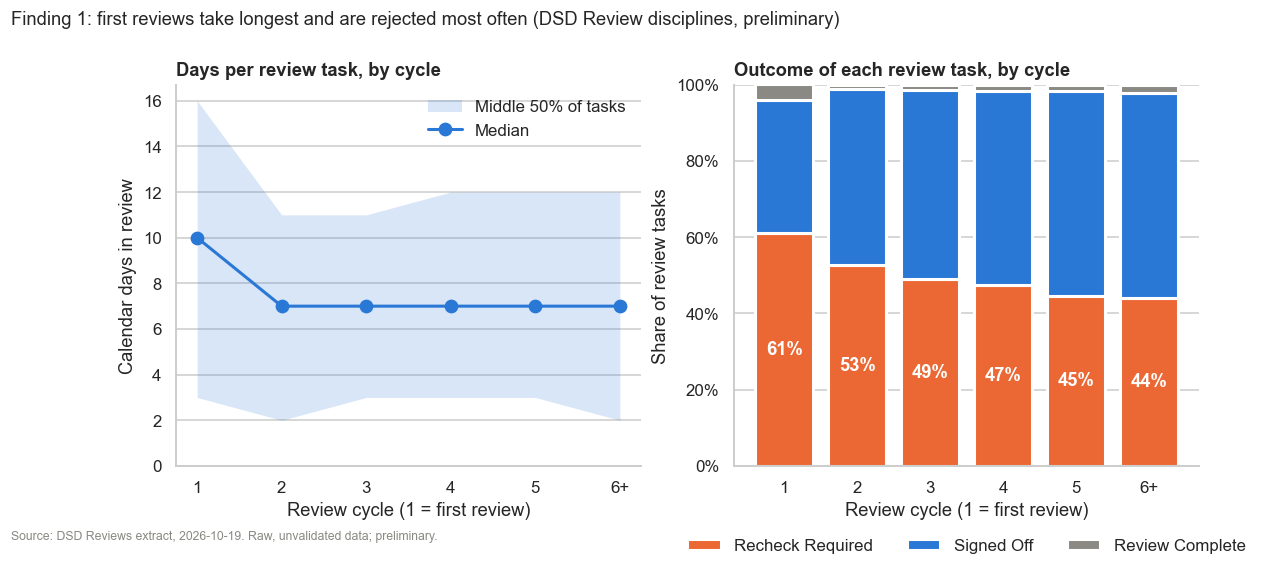

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
labels = [str(c) if c < 6 else "6+" for c in by_cycle.index]

ax1.fill_between(by_cycle.index, by_cycle["p25_days"], by_cycle["p75_days"], color=BLUE, alpha=0.18, linewidth=0, label="Middle 50% of tasks")
ax1.plot(by_cycle.index, by_cycle["median_days"], color=BLUE, marker="o", linewidth=2, markersize=8, label="Median")
ax1.set_xticks(by_cycle.index, labels)
ax1.grid(axis="x", visible=False)
ax2.grid(axis="x", visible=False)
ax1.set_ylim(0, None)
ax1.set_xlabel("Review cycle (1 = first review)")
ax1.set_ylabel("Calendar days in review")
ax1.set_title("Days per review task, by cycle")
ax1.legend(frameon=False, loc="upper right")

order = ["Recheck Required", "Signed Off", "Review Complete"]
colors = [ORANGE, BLUE, GRAY]
bottom = np.zeros(len(by_cycle))
for col, color in zip(order, colors):
    ax2.bar(labels, by_cycle[col], bottom=bottom, color=color, edgecolor="white", linewidth=2, label=col)
    bottom += by_cycle[col].values
for i, v in enumerate(by_cycle["Recheck Required"]):
    ax2.text(i, v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontweight="bold")
ax2.set_ylim(0, 100)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter())
ax2.set_xlabel("Review cycle (1 = first review)")
ax2.set_ylabel("Share of review tasks")
ax2.set_title("Outcome of each review task, by cycle")
ax2.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=3)

fig.suptitle("Finding 1: first reviews take longest and are rejected most often (DSD Review disciplines, preliminary)", x=0, ha="left", y=1.03, fontsize=12)
save(fig, "01_cycle_duration_outcome.png")
plt.show()

In [11]:
# Does the cycle-1 slowdown survive inside one review method? (Rapid Review is more common in cycle 1)
submit_only = cyc[cyc["TASK_METHOD_TYPE"] == "Submit"]
print("Median days, 'Submit' tasks only:")
print(submit_only.groupby("cycle")["DAYS_IN_REVIEW"].median())

Median days, 'Submit' tasks only:
cycle
1    12.0
2     8.0
3     8.0
4     8.0
5     8.0
6     7.0
Name: DAYS_IN_REVIEW, dtype: float64


**What this shows.**
- **Left panel:** how many calendar days a single review task takes, by cycle. The line is the median (the typical task), and the band covers the middle 50% of tasks.
- **Right panel:** how each review ended. "Recheck Required" means the reviewer found problems and the applicant must resubmit. "Signed Off" means that discipline approved. "Review Complete" is a less common closing status.

**Key finding.** The first review takes a median of **10 days**, against **7 days** for every later cycle. It also ends in "Recheck Required" **61%** of the time. Later cycles still get sent back often: **53%** at cycle 2 and still **44–45%** at cycles 5 and 6+. The slowdown holds within plain "Submit" reviews too (12 vs. 8 days), so it isn't just a difference in review methods.

**Why it matters.** The first cycle is where most time goes, because nearly every project has one and it is the longest. And "fixing the plans" doesn't reliably end the process: at every cycle, roughly half of reviews ask for another round. That repetition, more than any single slow review, is a natural suspect for long permit timelines.

**Caveat.** This only measures time **inside DSD's review**. It doesn't count the time the applicant spends fixing plans between cycles. Projects that reach cycle 5 are a selected group (often larger or harder projects), so the cycles aren't comparing the same projects. These are associations, not causes.

---
## Finding 2: Review method matters far more than the "express" label

Two columns describe how a review is handled:
- **`TASK_METHOD_TYPE`:** how the review happens. "Submit" = plans are dropped off and queued for review. "Rapid Review" = a fast-track review for smaller scopes. "Appointment" = a scheduled, in-person review.
- **`PROCESSING_TYPE`:** which track the project is on. "Standard", "Express", or "Expedite"; the names suggest faster handling for the last two.

The heatmap shows the median calendar days for each combination (DSD Review disciplines only), with the number of tasks in each cell.

In [12]:
method_order = ["Appointment", "Rapid Review", "Submit"]
proc_order = ["Standard", "Express", "Expedite"]

med = dsd.pivot_table(index="TASK_METHOD_TYPE", columns="PROCESSING_TYPE", values="DAYS_IN_REVIEW", aggfunc="median").loc[method_order, proc_order]
cnt = dsd.pivot_table(index="TASK_METHOD_TYPE", columns="PROCESSING_TYPE", values="DAYS_IN_REVIEW", aggfunc="size").loc[method_order, proc_order]
late = dsd.pivot_table(index="TASK_METHOD_TYPE", columns="PROCESSING_TYPE", values="late", aggfunc="mean").loc[method_order, proc_order]

print("Median days by method alone:")
print(dsd.groupby("TASK_METHOD_TYPE")["DAYS_IN_REVIEW"].median().loc[method_order])
print("\nTask counts:")
cnt

Median days by method alone:
TASK_METHOD_TYPE
Appointment     2.0
Rapid Review    2.0
Submit          9.0
Name: DAYS_IN_REVIEW, dtype: float64

Task counts:


PROCESSING_TYPE,Standard,Express,Expedite
TASK_METHOD_TYPE,,,
Appointment,677,453,16
Rapid Review,76482,1970,344
Submit,171103,97553,6867


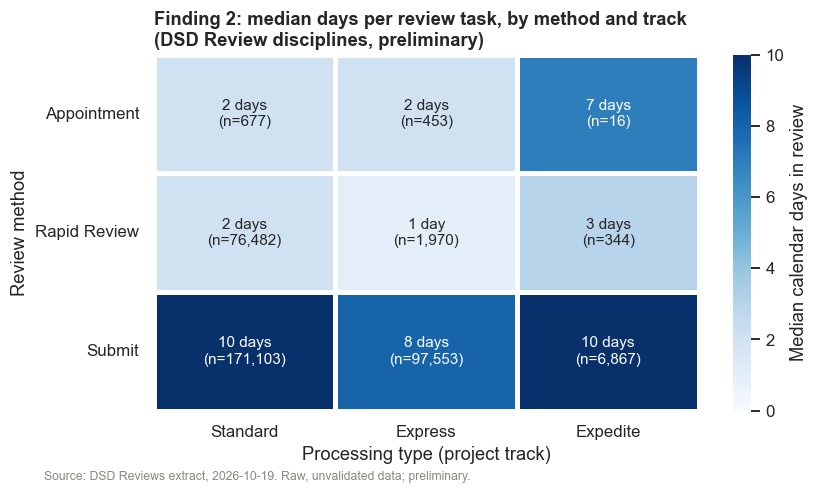

In [13]:
annot = med.map(lambda d: f"{d:.0f} day" if d == 1 else f"{d:.0f} days") + "\n(n=" + cnt.map(lambda n: f"{n:,}") + ")"

fig, ax = plt.subplots(figsize=(8, 4.2))
sns.heatmap(med, annot=annot, fmt="", cmap="Blues", vmin=0, linewidths=2, linecolor="white",
            cbar_kws={"label": "Median calendar days in review"}, ax=ax, annot_kws={"fontsize": 10})
ax.set_xlabel("Processing type (project track)")
ax.set_ylabel("Review method")
ax.set_title("Finding 2: median days per review task, by method and track\n(DSD Review disciplines, preliminary)")
ax.tick_params(axis="y", rotation=0)
save(fig, "02_method_processing_heatmap.png")
plt.show()

**What this shows.** Each cell is the typical (median) number of calendar days one review task took, for one combination of review method (rows) and project track (columns). Darker cells mean slower reviews. Reading **down** a column compares methods; reading **across** a row compares tracks.

**Key finding.** Method makes the big difference. "Rapid Review" and "Appointment" reviews typically finish in **2 days**, against **9 days** for "Submit" reviews (10 on the Standard track). Track makes much less difference. Within "Submit", Express (**8 days**) is only 2 days faster than Standard (**10 days**), and **Expedite (10 days) is no faster than Standard**.

**Why it matters.** If the goal is shorter reviews, *how* a review is done (queued drop-off vs. fast-track) seems to matter more than the label on the project. This is a useful lead for explaining delays, and for asking DSD which projects qualify for the faster methods.

**Caveat.** Projects aren't randomly assigned to methods. Rapid Review is meant for smaller or simpler scopes, so part of the gap is project size, not the method itself. Expedite has few tasks (about 7,200) and may be used for unusually complex projects. The Appointment row is small (n ≈ 1,400). About 7% of DSD tasks have no recorded method and are left out of the heatmap.

---
## Finding 3: Reviewers log about 1 hour of work on a task that stays open about 8 days

`TASK_HOURS_ACTUAL_END` is the number of hours staff recorded working on a review. `DAYS_IN_REVIEW` is the calendar time the task was open. Comparing them shows how much of a review's elapsed time is hands-on work. Tasks with 0 recorded hours are left out, since 0 is treated as unreliable (not logged), not as zero work. Nothing is imputed.

In [14]:
hours = dur[dur["TASK_HOURS_ACTUAL_END"] > 0].copy()
bins = [0, 0.5, 1, 2, 4, 8, np.inf]
bin_labels = ["≤0.5", "0.5–1", "1–2", "2–4", "4–8", ">8"]
hours["hours_bin"] = pd.cut(hours["TASK_HOURS_ACTUAL_END"], bins=bins, labels=bin_labels)

rho = hours["TASK_HOURS_ACTUAL_END"].corr(hours["DAYS_IN_REVIEW"], method="spearman")
# Work hours as a share of the working hours available while the task was open (8 h per calendar day, same-day tasks count as 1 day)
work_share = (hours["TASK_HOURS_ACTUAL_END"] / (hours["DAYS_IN_REVIEW"].clip(lower=1) * 8)).median()

print(f"Tasks with logged hours: {len(hours):,}")
print(f"Median logged hours: {hours['TASK_HOURS_ACTUAL_END'].median():.1f}   Median calendar days: {hours['DAYS_IN_REVIEW'].median():.0f}")
print(f"Spearman correlation (hours vs days): {rho:.2f}")
print(f"Median share of open time spent on logged work: {work_share:.1%}")
hours.groupby("hours_bin", observed=True)["DAYS_IN_REVIEW"].describe(percentiles=[0.25, 0.5, 0.75])[["count", "25%", "50%", "75%"]]

Tasks with logged hours: 384,895
Median logged hours: 1.0   Median calendar days: 8
Spearman correlation (hours vs days): 0.39
Median share of open time spent on logged work: 1.7%


,count,25%,50%,75%
hours_bin,,,,
≤0.5,108964.0,1.0,5.0,10.0
0.5–1,150855.0,4.0,8.0,14.0
1–2,76847.0,7.0,11.0,17.0
2–4,34066.0,9.0,14.0,25.0
4–8,10531.0,12.0,19.0,31.0
>8,3632.0,16.0,27.0,41.0


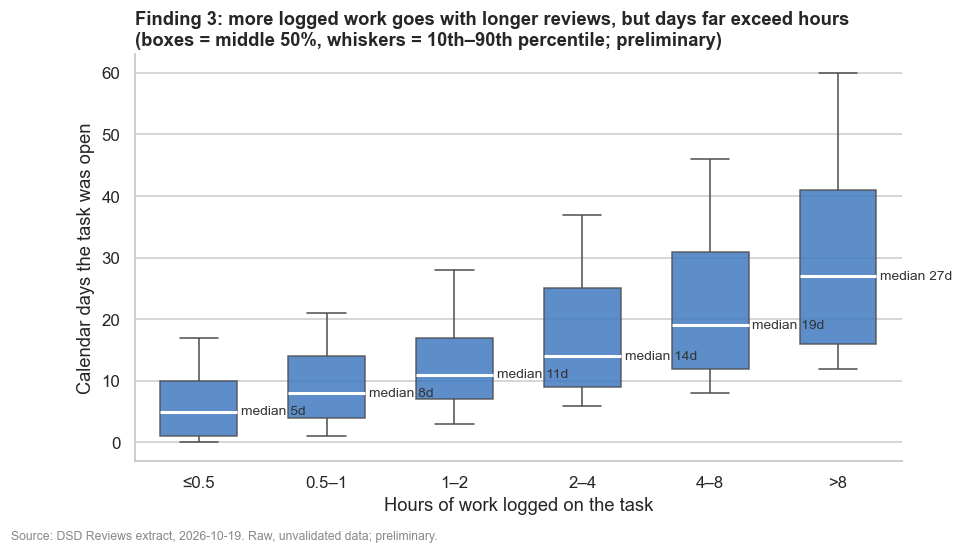

In [15]:
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.boxplot(data=hours, x="hours_bin", y="DAYS_IN_REVIEW", color=BLUE, showfliers=False,
            whis=(10, 90), width=0.6, boxprops={"alpha": 0.85}, medianprops={"color": "white", "linewidth": 2}, ax=ax)
medians = hours.groupby("hours_bin", observed=True)["DAYS_IN_REVIEW"].median()
for i, m in enumerate(medians):
    # Label to the right of each box so the text never sits on the fill
    ax.text(i + 0.33, m, f"median {m:.0f}d", va="center", ha="left", fontsize=9, color="#333333")
ax.set_xlabel("Hours of work logged on the task")
ax.set_ylabel("Calendar days the task was open")
ax.set_title("Finding 3: more logged work goes with longer reviews, but days far exceed hours\n(boxes = middle 50%, whiskers = 10th–90th percentile; preliminary)")
save(fig, "03_hours_vs_days.png")
plt.show()

**What this shows.** Tasks are grouped by how many hours of work staff logged. Each box shows the spread of calendar days those tasks stayed open: the box covers the middle half of tasks, the whiskers reach the 10th and 90th percentiles, and the label gives the median.

**Key finding.** The typical task has **1 hour** of logged work but stays open **8 calendar days**. At the median, logged work fills under **2%** of the working hours that pass while a task is open. More work does go with longer reviews (Spearman correlation **0.39**, a moderate link). Even so, a task with half an hour of work still typically sits open **5 days**.

**Why it matters.** This suggests that most of a review's elapsed time is **waiting** (in a queue, or for a reviewer's other work), not hands-on review. If so, delays may depend more on workload and scheduling than on how hard individual plans are to check.

**Caveat.** Logged hours depend on staff recording time consistently; about 10% of closed tasks show 0 hours and were excluded. Days are calendar days, so weekends and holidays count, and that alone inflates elapsed time relative to work. The 8-hour-per-day share is a rough yardstick, not a staffing measure.

---
## Finding 4: Review speed varies a lot by discipline, and outside reviewers are slowest

We compare calendar days in review across the 20 disciplines with the most finished tasks, sorted from fastest to slowest median. Colors show the **discipline category**: DSD's own reviewers, other City departments, or external agencies and utilities.

In [16]:
print("Median days by discipline category:")
print(dur.groupby("DISCIPLINE_CATEGORY")["DAYS_IN_REVIEW"].describe(percentiles=[0.5, 0.9])[["count", "50%", "90%"]])

top20 = dur["DISCIPLINE"].value_counts().head(20).index
top = dur[dur["DISCIPLINE"].isin(top20)]
disc_stats = top.groupby("DISCIPLINE").agg(
    category=("DISCIPLINE_CATEGORY", "first"),
    tasks=("DAYS_IN_REVIEW", "size"),
    median_days=("DAYS_IN_REVIEW", "median"),
    p90_days=("DAYS_IN_REVIEW", lambda s: s.quantile(0.9)),
    late_pct=("late", lambda s: round(s.mean() * 100, 1)),
).sort_values("median_days")
disc_stats

Median days by discipline category:
                               count   50%   90%
DISCIPLINE_CATEGORY                             
DSD Review                  391751.0   8.0  24.0
External Agency or Utility    5615.0  21.0  57.0
Other City Department        30673.0  14.0  29.0


,category,tasks,median_days,p90_days,late_pct
DISCIPLINE,,,,,
Review,DSD Review,6326,0.0,45.0,53.3
DSD-Electrical,DSD Review,36463,4.0,15.0,13.4
DSD-Right of Way Dry Utilities,DSD Review,16387,5.0,12.0,0.3
DSD-Fire Alarm,DSD Review,6359,6.0,15.0,17.3
DSD-Fire Suppression,DSD Review,14913,7.0,18.0,23.9
DSD-Mechanical,DSD Review,17239,7.0,17.0,11.8
DSD-Structural,DSD Review,52486,8.0,22.0,23.2
DSD-Planning Review,DSD Review,48083,8.0,27.0,30.8
DSD-Addressing,DSD Review,12772,8.0,15.0,11.8


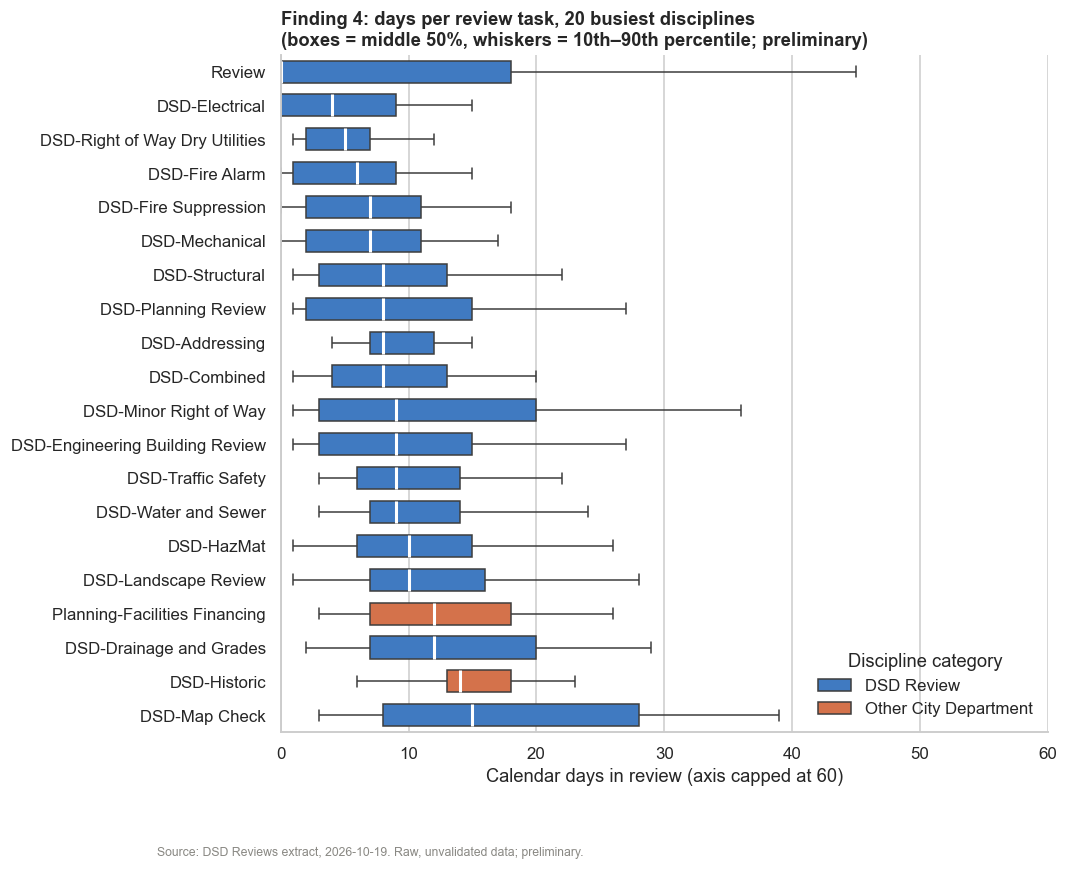

In [17]:
order = disc_stats.index.tolist()
palette = {"DSD Review": BLUE, "Other City Department": ORANGE, "External Agency or Utility": AQUA}

fig, ax = plt.subplots(figsize=(9, 8))
sns.boxplot(data=top, y="DISCIPLINE", x="DAYS_IN_REVIEW", order=order, hue="DISCIPLINE_CATEGORY",
            palette=palette, dodge=False, showfliers=False, whis=(10, 90), width=0.65,
            medianprops={"color": "white", "linewidth": 2}, ax=ax)
ax.set_xlim(0, 60)
ax.set_xlabel("Calendar days in review (axis capped at 60)")
ax.set_ylabel("")
ax.set_title("Finding 4: days per review task, 20 busiest disciplines\n(boxes = middle 50%, whiskers = 10th–90th percentile; preliminary)")
ax.legend(title="Discipline category", frameon=False, loc="lower right")
save(fig, "04_discipline_duration.png")
plt.show()

**What this shows.** Each row is one reviewing specialty, sorted by its median review time. The box covers the middle half of that discipline's tasks, and the whiskers reach the 10th and 90th percentiles.
- **DSD Review** (blue): DSD's own reviewers.
- **Other City Department** (orange): other City offices, such as Facilities Financing.
- **External Agency or Utility:** outside groups. None reach the top 20 by volume, but their category median is reported below.

**Key finding.**
- **By discipline:** Electrical reviews typically take **4 days** and Right of Way Dry Utilities **5**, while Map Check takes **15** and DSD-Historic **14**.
- **By category:** DSD's own disciplines have a median of **8 days**, other City departments **14**, and external agencies or utilities **21**, more than 2.5× DSD's.
- **DSD-Historic** has an unusually narrow box (most tasks take 13–18 days), which suggests a fixed timeline rather than a variable queue.
- **The generic "Review" discipline** has a median of 0 days but a very long tail. It is a one-step sign-off used for simple permits, such as noise permits.

**Why it matters.** A project's total wait depends on its *slowest* required discipline, not the average one. Projects that need outside agencies, historic review, or map check may be held up by those reviews even when the rest finish quickly.

**Caveat.** Disciplines review different kinds of projects, so they aren't directly comparable: Map Check sees subdivision maps, and Electrical sees many small permits. The x-axis is capped at 60 days for readability, which hides the longest tails (the 90th percentile is listed in the table above). DSD-Historic is classed as "Other City Department" in the data and is left as is.

---
## Finding 5: On-time performance swings a lot over time

We count review tasks by the month they began, and for finished tasks, the share completed after their due date. Months from September 2026 on are left out: many of those tasks are still open, so the finished ones would make those months look faster than they are. Volume counts include all tasks (open and abandoned too). Lateness uses only finished tasks.

In [18]:
LAST_FULL_MONTH = pd.Period("2026-08", freq="M")

volume = df.groupby(df["BEGIN_DATE"].dt.to_period("M")).size().rename("tasks_begun")
lateness = dur.groupby(dur["BEGIN_DATE"].dt.to_period("M")).agg(
    pct_late=("late", lambda s: s.mean() * 100),
    median_days=("DAYS_IN_REVIEW", "median"),
)
monthly = volume.to_frame().join(lateness)
monthly = monthly[monthly.index <= LAST_FULL_MONTH]

# Share of tasks still open, per start month: shows why recent months are excluded
open_share = df.groupby(df["BEGIN_DATE"].dt.to_period("M"))["END_DATE"].apply(lambda s: s.isna().mean() * 100)
print("Share of tasks still open, by start month (last 4 months):")
print(open_share.tail(4).round(1))

rho_month = monthly["tasks_begun"].corr(monthly["pct_late"], method="spearman")
print(f"\nSpearman correlation, monthly volume vs % late: {rho_month:.2f}")
print("Lowest and highest % late months:")
print(monthly["pct_late"].round(1).sort_values().iloc[[0, 1, 2, -3, -2, -1]])

Share of tasks still open, by start month (last 4 months):
BEGIN_DATE
2026-07     0.9
2026-08     1.4
2026-09     7.1
2026-10    49.3
Freq: M, Name: END_DATE, dtype: float64

Spearman correlation, monthly volume vs % late: -0.27
Lowest and highest % late months:
BEGIN_DATE
2024-04    14.8
2024-09    15.3
2024-05    16.4
2026-01    36.5
2023-04    37.5
2023-03    44.3
Freq: M, Name: pct_late, dtype: float64


In [19]:
by_year = monthly.groupby(monthly.index.year).agg(avg_tasks_per_month=("tasks_begun", "mean"), median_pct_late=("pct_late", "median")).round(1)
by_year

,avg_tasks_per_month,median_pct_late
BEGIN_DATE,,
2023,7175.2,34.5
2024,9656.7,18.4
2025,10913.6,29.4
2026,10714.1,29.3


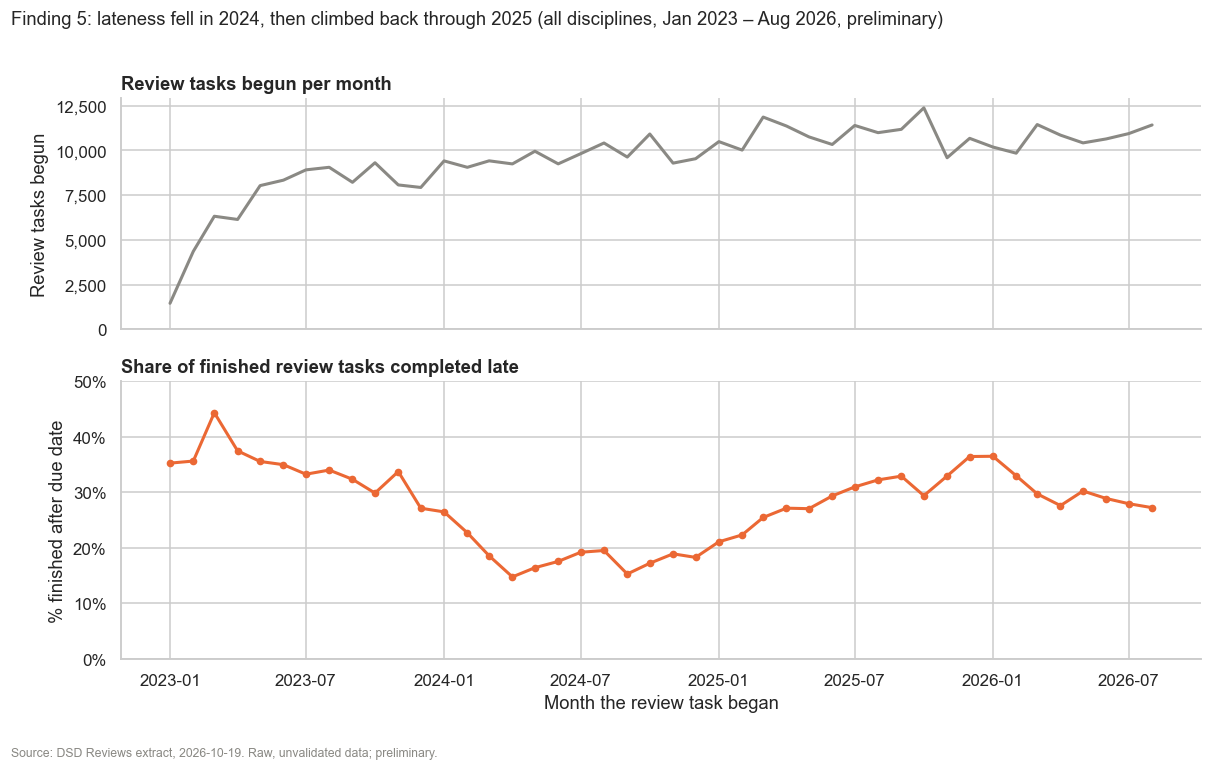

In [20]:
x = monthly.index.to_timestamp()
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True, gridspec_kw={"height_ratios": [1, 1.2]})

ax1.plot(x, monthly["tasks_begun"], color=GRAY, linewidth=2)
ax1.set_ylabel("Review tasks begun")
ax1.set_ylim(0, None)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax1.set_title("Review tasks begun per month")

ax2.plot(x, monthly["pct_late"], color=ORANGE, linewidth=2, marker="o", markersize=4)
ax2.set_ylabel("% finished after due date")
ax2.set_ylim(0, 50)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter())
ax2.set_title("Share of finished review tasks completed late")
ax2.set_xlabel("Month the review task began")

fig.suptitle("Finding 5: lateness fell in 2024, then climbed back through 2025 (all disciplines, Jan 2023 – Aug 2026, preliminary)",
             x=0, ha="left", y=1.01, fontsize=12)
fig.tight_layout()
save(fig, "05_monthly_volume_lateness.png")
plt.show()

**Check: is this just a change in the mix of cycles?** Early 2023 is mostly first reviews, and Finding 1 showed those are the slowest. So we repeat the yearly comparison separately for first reviews and for later cycles.

In [21]:
recent = dur[dur["BEGIN_DATE"].dt.to_period("M") <= LAST_FULL_MONTH]
first_review = recent["DISCIPLINE_CYCLE_NUMBER"] == 1
pd.DataFrame({
    "share_first_reviews": first_review.groupby(recent["BEGIN_DATE"].dt.year).mean(),
    "pct_late_cycle_1": recent[first_review].groupby(recent["BEGIN_DATE"].dt.year)["late"].mean(),
    "pct_late_cycle_2plus": recent[~first_review].groupby(recent["BEGIN_DATE"].dt.year)["late"].mean(),
}).mul(100).round(1)

,share_first_reviews,pct_late_cycle_1,pct_late_cycle_2plus
BEGIN_DATE,,,
2023,69.5,34.4,33.1
2024,50.4,18.3,19.1
2025,48.0,29.5,28.5
2026,45.8,30.4,29.8


**What this shows.**
- **Top panel:** how many review tasks started each month.
- **Bottom panel:** of the tasks that finished, the share completed after their **due date**, the target finish date recorded on each task (usually about 10 calendar days after it starts).

**Key finding.**
- **Swing over time:** lateness dropped from about **35%** of tasks in 2023 to a low of **15%** in April and September 2024. It then climbed back to **36–37%** in December 2025 and January 2026, and has eased to about **27%** by mid-2026.
- **Not a simple volume story:** volume rose over the same period, from about 7,200 to about 10,900 tasks a month, but month-to-month volume and lateness are only weakly linked (Spearman **−0.27**, in the opposite direction from "busier means later"). 2024 had more tasks than 2023 yet far fewer late ones.
- **Not a cycle-mix effect:** the same rise and fall shows up for first reviews alone (34% → 18% → 30%) and for later cycles alone (33% → 19% → 29%).

**Why it matters.** The same kind of review was more than twice as likely to miss its due date in some periods as in others. That points to something that changes over time, such as staffing, process changes, policy, or a backlog, rather than anything about individual projects. Pinning down what happened in 2024 could be one of the most useful leads for explaining delays.

**Caveat.**
- **Early 2023:** the volume ramp in early 2023 suggests the extract mostly contains records opened from 2023 on. Early months may be incomplete.
- **Recent months:** they include only tasks that have finished so far. We cut the series at August 2026 for this reason.
- **Definition:** "late" is measured against the recorded due date, which may be set or changed in ways we can't see. The typical allowance was slightly longer in 2023 (11 days vs. 10).
- **Interpretation:** this is a time pattern, not a cause.

---
## Relationships checked and dropped

- **Estimated vs. actual hours:** a very weak link (Spearman ≈ 0.15). 65% of estimates are exactly 2.0 hours, which looks like a default value, so the comparison mostly reflects data entry.
- **Processing type vs. duration (on its own):** Express and Standard have the same median (8 days). The interesting part is covered in Finding 2.
- **Record type vs. number of cycles:** large differences (Building Construction has a median of 3 cycles, Photovoltaic 1), but this is expected given project complexity and is already covered in `01_reviews_target.ipynb`.
- **Outcome vs. review method:** Appointment reviews are signed off more often (72% vs. 43% for Submit), but there are few of them, and it repeats the size story from Finding 2.
- **Lateness vs. review method:** Appointment tasks look 75% late, but their due date is set to the start date (0 days allowed). That is a recording artifact, not a real finding.
- **Duration by processing type × outcome:** small differences that don't change any conclusion.

---
## Data notes

- **Source:** `data/02_Data Mazen Abugharbieh/Activity_Tables/DSD_Reviews_2026-10-19.csv`, 438,373 rows × 20 columns. It is loaded with `pandas.read_csv`, which handles line breaks inside quoted cells. The original file is not modified.
- **Status:** raw, unvalidated extract, for research only. All results are preliminary and not official City or DSD findings.
- **Cleaning steps and rows removed** (from the `steps_table` output above):

| Step | Applies to | Rows before | Rows removed | Rows after |
|---|---|---|---|---|
| Drop duplicate RECORD_ID + TASK_TYPE + DISCIPLINE_CYCLE_NUMBER (keep the non-abandoned copy) | All analysis | 438,373 | 459 | 437,914 |
| Drop DISCIPLINE_CATEGORY == "Workflow Step" | All analysis | 437,914 | 2,213 | 435,701 |
| Drop ABANDONED_TASK == 1 | Duration and lateness only | 435,701 | 2,667 | 433,034 |
| Drop open tasks (no END_DATE) | Duration and lateness only | 433,034 | 4,368 | 428,666 |
| Drop negative DAYS_IN_REVIEW | Duration and lateness only | 428,666 | 627 | 428,039 |

- **Other choices:**
  - `"undefined"` was set to missing in `PROCESSING_TYPE` (4 values) and `TASK_METHOD_TYPE` (1,025 values).
  - "Canceled" was merged into "Cancelled" in `RECORD_STATUS` (1 row).
  - DSD-Historic was left in "Other City Department" as recorded.
  - `TASK_HOURS_ACTUAL_END == 0` was treated as unreliable and excluded from the hours analysis (Finding 3). Missing estimated hours were not imputed.
  - Findings 1 and 2 use DSD Review disciplines only; Findings 3–5 use all disciplines.
  - No random sampling was used; every plot uses all rows in its subset.
- **Definitions:**
  - **Duration** = `DAYS_IN_REVIEW`, in calendar days.
  - **Late** = finished on a calendar date after `TASK_DUE_DATE`.